# Bài 2 (Trang 28) - Dữ liệu Bank Marketing
## Câu 4: Khảo sát sự liên quan giữa Hình thức liên lạc (contact), Học vấn (education) với khả năng đăng ký, phân biệt theo marital

**Sinh viên:** Trần Đình Võ - **MSSV:** 6451071088

In [1]:
HO_TEN = "Trần Đình Võ"
MSSV = "6451071088"
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")

Họ tên: Trần Đình Võ - MSSV: 6451071088


### Import thư viện và đọc dữ liệu

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

df = pd.read_csv("../Dataset/bank/bank.csv", sep=";")

### Các bước xử lý của câu 1 → 3 (chuẩn bị dữ liệu)

In [3]:
# Trong bộ dữ liệu, giá trị thiếu được ghi là 'unknown' -> chuyển về NaN
df = df.replace("unknown", np.nan)

df["subscribed"] = (df["y"] == "yes").astype(int)

### Câu 4: Khảo sát sự liên quan giữa Hình thức liên lạc (contact), Học vấn (education) với khả năng đăng ký, phân biệt theo marital

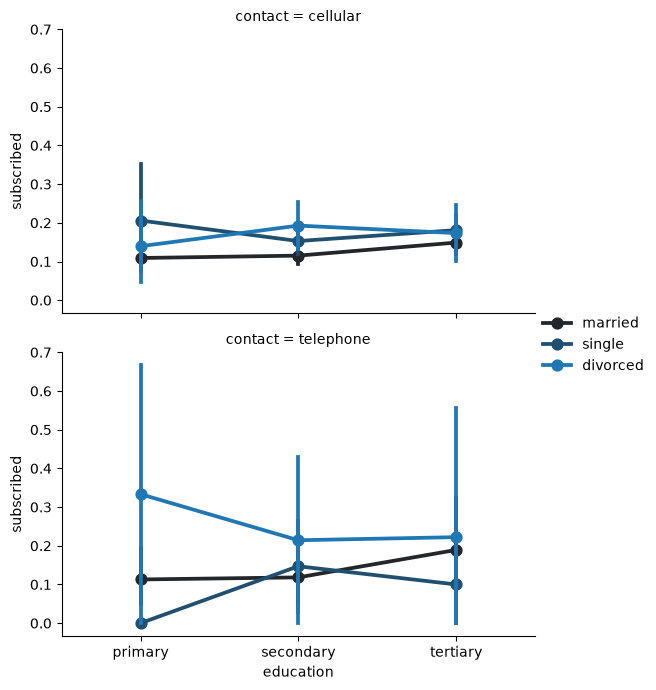

In [4]:
FacetGrid = sns.FacetGrid(df, row="contact", height=3.5, aspect=1.6)
FacetGrid.map(sns.pointplot, "education", "subscribed", "marital", palette=None,
              order=["primary", "secondary", "tertiary"], hue_order=["married", "single", "divorced"])
FacetGrid.add_legend()
plt.show()

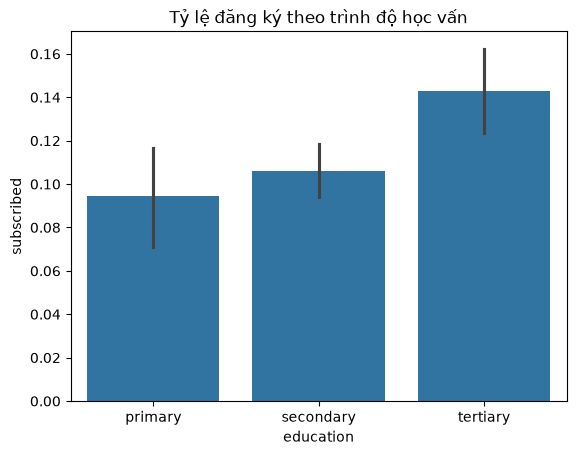

In [5]:
sns.barplot(x="education", y="subscribed", data=df, order=["primary", "secondary", "tertiary"])
plt.title("Tỷ lệ đăng ký theo trình độ học vấn")
plt.show()

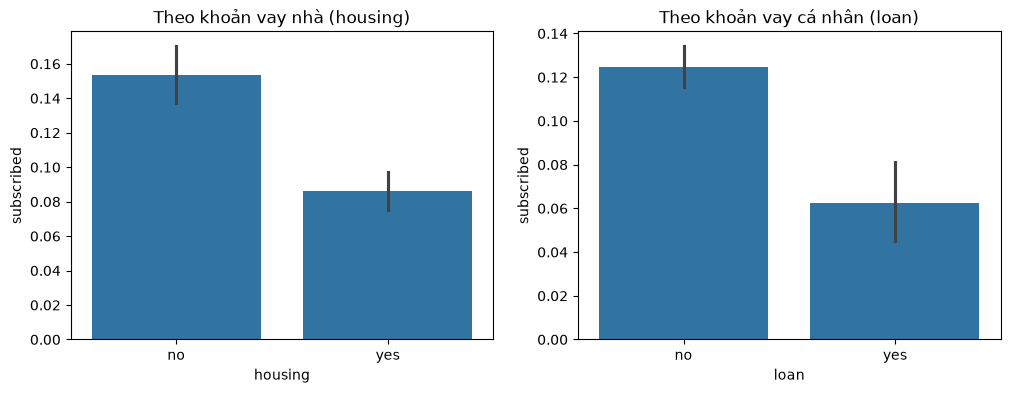

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x="housing", y="subscribed", data=df, ax=axes[0]).set_title("Theo khoản vay nhà (housing)")
sns.barplot(x="loan", y="subscribed", data=df, ax=axes[1]).set_title("Theo khoản vay cá nhân (loan)")
plt.show()

In [7]:
df.pivot_table(index="contact", columns="marital", values="subscribed", aggfunc="mean").round(3)

marital,divorced,married,single
contact,,,
cellular,0.181,0.126,0.165
telephone,0.235,0.141,0.115


### Nhận xét
- Trình độ học vấn càng cao thì tỷ lệ đăng ký càng cao (tertiary cao nhất).
- Liên lạc qua cellular/telephone có tỷ lệ đăng ký cao hơn nhiều so với nhóm không rõ hình thức liên lạc.
- Khách hàng không có khoản vay nhà (housing) hoặc vay cá nhân (loan) đăng ký nhiều hơn.